In [12]:
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import cross_val_score

In [2]:
X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1,noise=20,random_state=13)

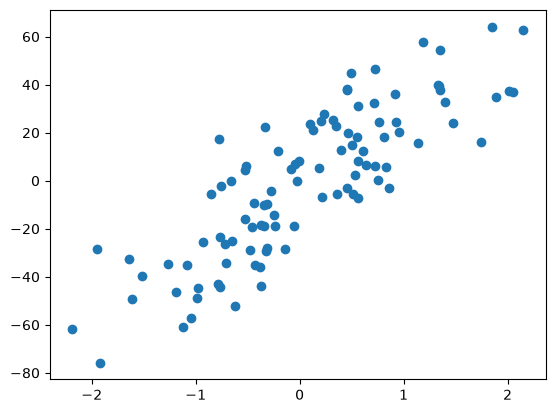

In [3]:
plt.scatter(X,y)

In [4]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [13]:
from sklearn.linear_model import LinearRegression

In [6]:
lr = LinearRegression()

In [7]:
lr.fit(X_train,y_train)
print(lr.coef_)
print(lr.intercept_)

[28.12597332]
-2.271014426178382


In [31]:
np.mean(cross_val_score(lr,X,y,scoring='r2',cv=10))

np.float64(0.6375011587464419)

In [34]:
class GDRegressor:
    
    def __init__(self,learning_rate,epochs):
        self.m = 100
        self.b = -120 # kahi se bhi strt kre iwth correct lr and epoch rate we will get close to correct 
        self.lr = learning_rate
        self.epochs = epochs
        
    def fit(self,X,y):
        for i in range(self.epochs):
            loss_slope = -2 * np.sum(y - self.m*X.ravel() - self.b)
            self.b = self.b - (self.lr * loss_slope)
            print(loss_slope,self.b)
        print(self.b)
        
    def predict(self,X):
        return self.m * X + self.b

In [35]:
gd = GDRegressor(0.1,10)
gd.fit(X_train,y_train)

-18254.207774488757 1705.420777448876
273813.1166173314 -25675.890884284265
-4107196.749259971 385043.7840417129
61607951.238899566 -5775751.339848244
-924119268.5834935 86636175.5185011
13861789028.752401 -1299542727.3567393
-207926835431.28604 19493140815.771866
3118902531469.291 -292397112331.1573
-46783537972039.375 4385956684872.7803
701753069580590.8 -65789350273186.3
-65789350273186.3


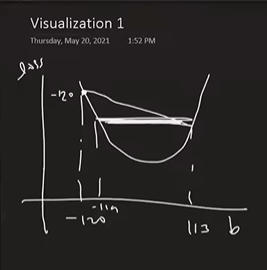

thw thing is its going bak and forth bcos of less lr and epoch 

In [27]:
gd = GDRegressor(0.001,50) #if we do lr less and epoch more better result 

In [28]:
gd.fit(X_train,y_train)

-18836.686096466117 -101.16331390353389
-15822.81632103154 -85.34049758250235
-13291.165709666493 -72.04933187283586
-11164.579196119856 -60.884752676716005
-9378.246524740678 -51.50650615197533
-7877.72708078217 -43.62877907119316
-6617.290747857021 -37.01148832333614
-5558.5242281999 -31.452964095136238
-4669.160351687915 -26.783803743448324
-3922.094695417849 -22.861709048030477
-3294.559544150993 -19.567149503879484
-2767.4300170868346 -16.79971948679265
-2324.6412143529415 -14.47507827243971
-1952.6986200564709 -12.52237965238324
-1640.2668408474356 -10.882112811535805
-1377.824146311846 -9.504288665223958
-1157.3722829019507 -8.346916382322007
-972.1927176376383 -7.374723664684369
-816.6418828156161 -6.558081781868753
-685.9791815651178 -5.872102600303636
-576.2225125146989 -5.295880087788937
-484.0269105123471 -4.81185317727659
-406.58260483037157 -4.405270572446218
-341.52938805751216 -4.063741184388706
-286.88468596831024 -3.776856498420396
-240.98313621338053 -3.5358733622070

In [29]:
y_pred = gd.predict(X_test)
from sklearn.metrics import r2_score
r2_score(y_test,y_pred)


0.6345554868871728

### Understanding how things behave 

1.
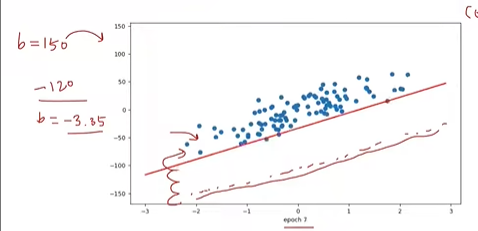

from wahtever b we take it comes closer to the best fit line with more epochs 

2.

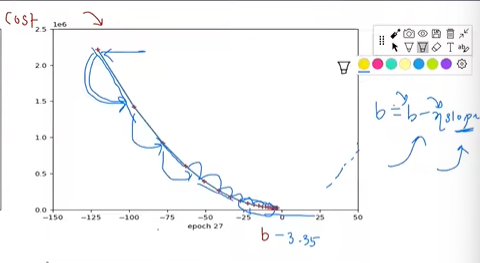

when getting closer to slope tiny steps so taht we odnt miss the solution 

3.
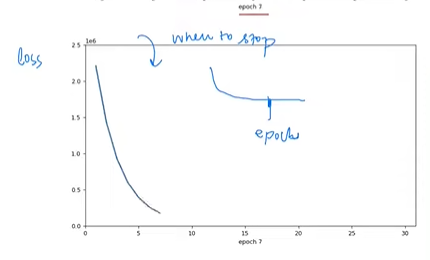

when loss gets constant means now b is not affecting the graph so doingmore iteration is not gonaa help STOP 

4.

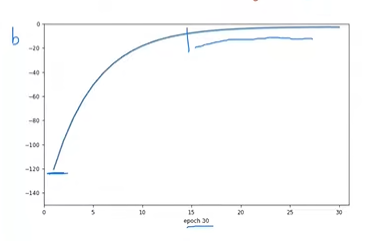


### Effects of Learning Rate

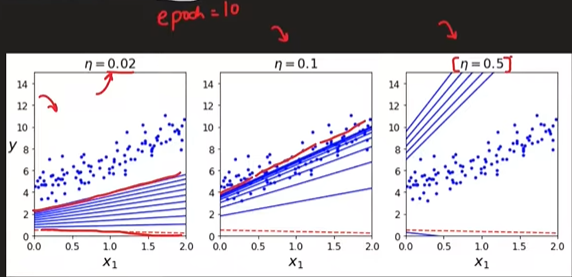
1. too less lr => we can never reach the BFT => more epoch more iterations slower model 
2. perfect
3. lr too high => solution missed
from red dotted line we are trying to get closer to blue lines

## Gradient Descent Visualisation


Till now we did changes in one of m/b keeping one constant lets mix the two and see the real gd

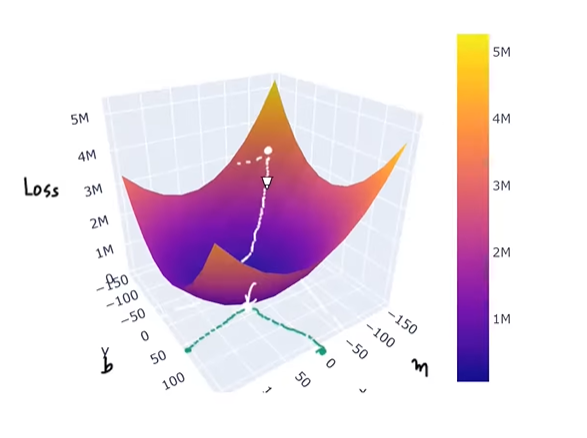
 

here goal is to find minimum loss we is the bottom of this vvalley lets say we strted at white pt on top we need to descrese m & b in such a way that we reach the bottom of it 